In [1]:
# --- LÍNEAS MÁGICAS ---
%load_ext autoreload
%autoreload 2

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats
from IPython.display import display
from sklearn.model_selection import StratifiedShuffleSplit

In [2]:
# 1. Cargar los datos crudos descargados del script de ingesta
data_path = os.path.join("..", "data", "raw", "train.csv")
df = pd.read_csv(data_path)

print(f"Total de datos originales: {df.shape}")

# 2. Limpieza: quitar espacios en blanco de los textos de tráfico para asegurar buena estratificación
if 'Road_traffic_density' in df.columns:
    df['Road_traffic_density'] = df['Road_traffic_density'].astype(str).str.strip()

# 3. Aplicar Muestreo Estratificado (80% Entrenamiento, 20% Prueba)
split = StratifiedShuffleSplit(n_splits=1, test_size=0.2, random_state=42)

for train_index, test_index in split.split(df, df['Road_traffic_density']):
    strat_train_set = df.loc[train_index]
    strat_test_set = df.loc[test_index]

print(f"Datos de Entrenamiento (80%): {strat_train_set.shape}")
print(f"Datos de Prueba (20%): {strat_test_set.shape}\n")

# 4. Verificar que la proporción de tráfico es idéntica en ambos conjuntos
proporcion_original = df['Road_traffic_density'].value_counts(normalize=True)
proporcion_train = strat_train_set['Road_traffic_density'].value_counts(normalize=True)
proporcion_test = strat_test_set['Road_traffic_density'].value_counts(normalize=True)

comparacion = pd.DataFrame({
    'Universo Original (%)': proporcion_original * 100,
    'Set Entrenamiento (%)': proporcion_train * 100,
    'Set Prueba (%)': proporcion_test * 100
}).round(2)

display(comparacion)

Total de datos originales: (45593, 20)
Datos de Entrenamiento (80%): (36474, 20)
Datos de Prueba (20%): (9119, 20)



,Universo Original (%),Set Entrenamiento (%),Set Prueba (%)
Road_traffic_density,,,
Low,33.95,33.94,33.95
Jam,31.02,31.02,31.02
Medium,24.01,24.01,24.00
High,9.71,9.71,9.71
NaN,1.32,1.32,1.32


In [3]:
print("=====================================================================")
print(" FASE: PREPARACIÓN Y PRE-LIMPIEZA DE DATOS PARA EDA")
print("=====================================================================\n")

# 1. GUARDAR LA SEPARACIÓN ESTRATIFICADA (Para Pipeline)
processed_dir = os.path.join("..", "data", "processed")
os.makedirs(processed_dir, exist_ok=True)
strat_train_set.to_csv(os.path.join(processed_dir, "train_processed.csv"), index=False)
strat_test_set.to_csv(os.path.join(processed_dir, "test_processed.csv"), index=False)
print("Splits guardados en data/processed/")

# 2. PRE-LIMPIEZA (REGEX Y NULOS) PARA GRÁFICOS
train_eda = strat_train_set.copy()

# Regex para extraer solo números
columnas_num_sucias = ['Time_taken(min)', 'Delivery_person_Age', 'Delivery_person_Ratings', 'multiple_deliveries', 'Vehicle_condition']
for col in columnas_num_sucias:
    if col in train_eda.columns:
        train_eda[col] = train_eda[col].astype(str).str.extract(r'(\d+\.?\d*)')[0]
        train_eda[col] = pd.to_numeric(train_eda[col], errors='coerce')

# Limpiar espacios invisibles y "NaN" en variables categóricas
columnas_cat_clave = ['Road_traffic_density', 'Weatherconditions', 'Type_of_vehicle', 'Festival', 'City']
for col in columnas_cat_clave:
    if col in train_eda.columns:
        train_eda[col] = train_eda[col].astype(str).str.strip()
        train_eda[col] = train_eda[col].replace(['NaN', 'nan', 'None', ''], np.nan)

# Base limpia sin nulos para Pearson y ANOVA
df_limpio = train_eda.dropna(subset=['Time_taken(min)']).copy()
print("Datos pre-limpiados temporalmente en memoria para gráficas.")

 FASE: PREPARACIÓN Y PRE-LIMPIEZA DE DATOS PARA EDA

Splits guardados en data/processed/
Datos pre-limpiados temporalmente en memoria para gráficas.


 FASE: CÁLCULOS ESTADÍSTICOS Y MATRIZ DE CORRELACIÓN



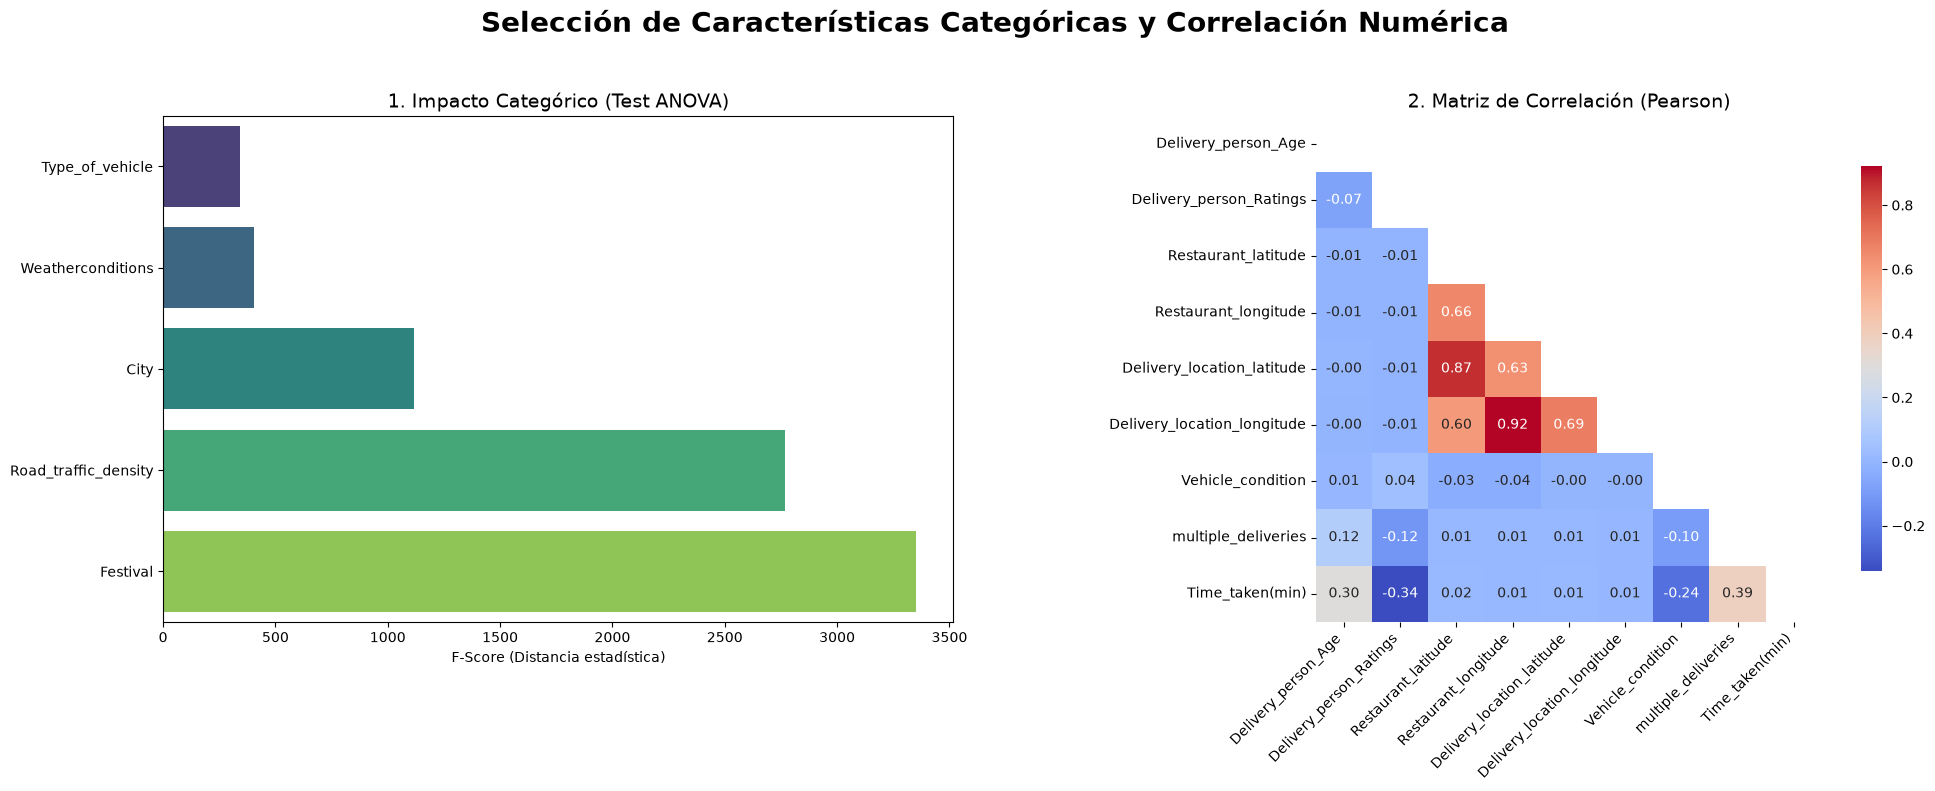

In [4]:
print("=====================================================================")
print(" FASE: CÁLCULOS ESTADÍSTICOS Y MATRIZ DE CORRELACIÓN")
print("=====================================================================\n")

# 1. ANOVA (Categóricas vs Tiempo)
resultados_anova = []
for col in columnas_cat_clave:
    if col in df_limpio.columns:
        grupos = [df_limpio[df_limpio[col] == cat]['Time_taken(min)'].values for cat in df_limpio[col].dropna().unique()]
        if len(grupos) > 1:
            resultados_anova.append({'Variable Categórica': col, 'F-Score': stats.f_oneway(*grupos)[0]})

df_anova = pd.DataFrame(resultados_anova).sort_values(by='F-Score', ascending=True)

# 2. PEARSON (Matriz Numérica)
variables_numericas = df_limpio.select_dtypes(include=[np.number])
corr = variables_numericas.corr()

# 3. GRÁFICO CATEGÓRICO Y MATRIZ
fig1, axes1 = plt.subplots(1, 2, figsize=(20, 8))
fig1.suptitle('Selección de Características Categóricas y Correlación Numérica', fontsize=20, fontweight='bold')

# Gráfico Categórico (ANOVA)
sns.barplot(x='F-Score', y='Variable Categórica', data=df_anova, ax=axes1[0], palette='viridis', hue='Variable Categórica', legend=False)
axes1[0].set_title('1. Impacto Categórico (Test ANOVA)', fontsize=14)
axes1[0].set_xlabel('F-Score (Distancia estadística)')
axes1[0].set_ylabel('')

# Matriz Térmica de Pearson
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, cmap='coolwarm', fmt=".2f", cbar_kws={"shrink": .8}, ax=axes1[1], square=True)
axes1[1].set_title('2. Matriz de Correlación (Pearson)', fontsize=14)
axes1[1].set_xticklabels(axes1[1].get_xticklabels(), rotation=45, ha='right')

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()

 FASE: ANÁLISIS VISUAL CATEGÓRICO (ANOVA)



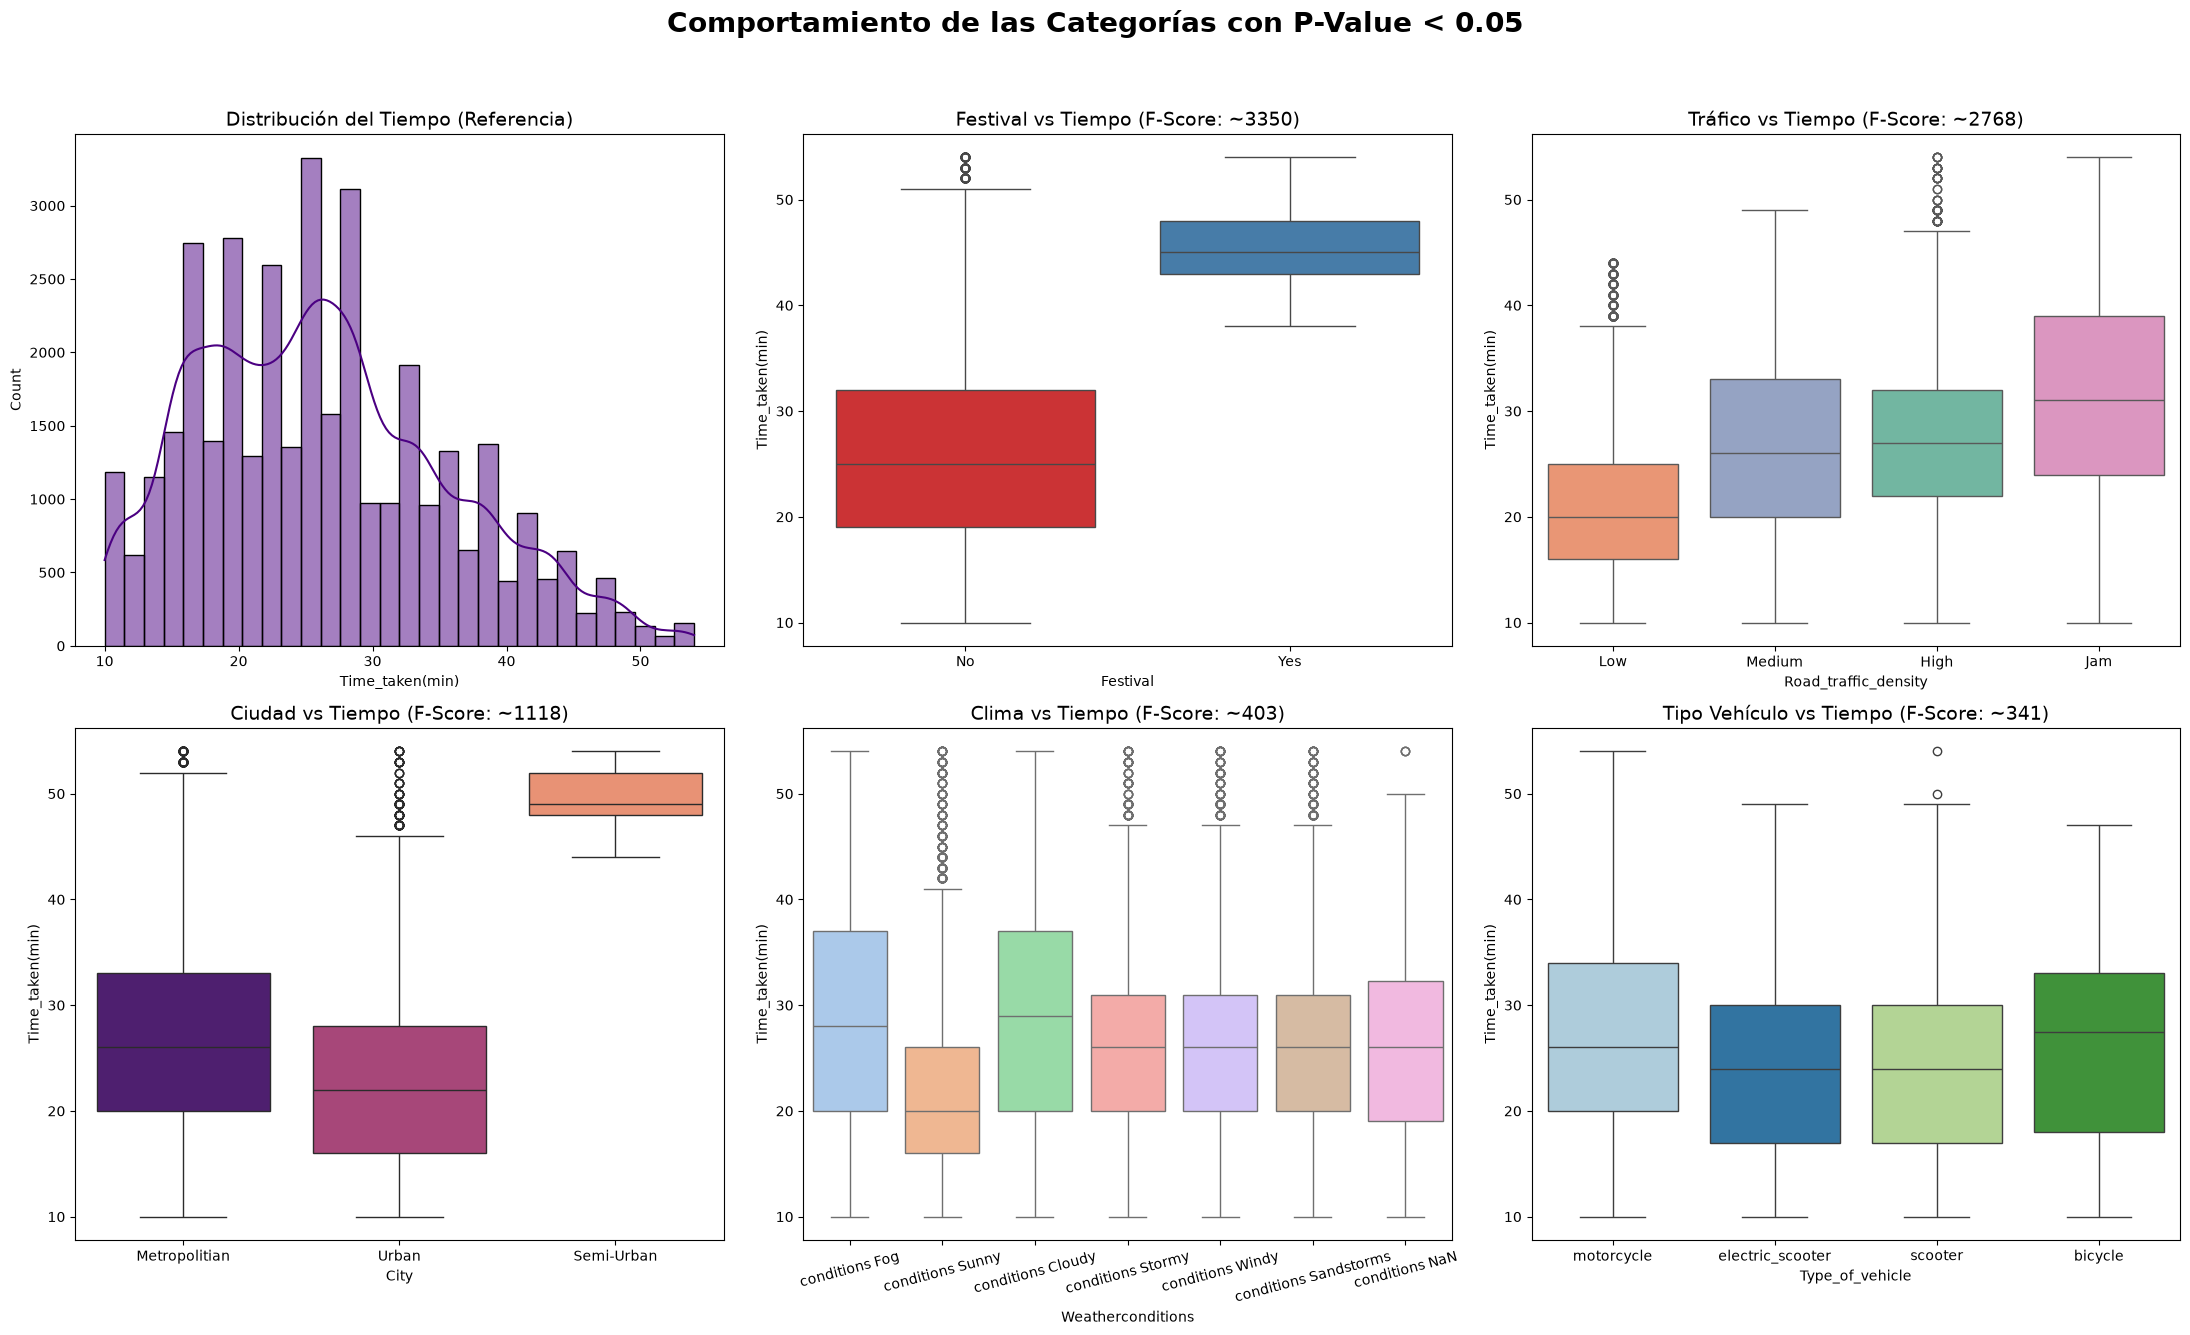

In [5]:
print("=====================================================================")
print(" FASE: ANÁLISIS VISUAL CATEGÓRICO (ANOVA)")
print("=====================================================================\n")

fig_cat = plt.figure(figsize=(22, 14))
fig_cat.suptitle('Comportamiento de las Categorías con P-Value < 0.05', fontsize=20, fontweight='bold', y=0.98)

# 1. Objetivo Base
ax1 = plt.subplot(2, 3, 1)
sns.histplot(df_limpio['Time_taken(min)'], kde=True, bins=30, color='indigo', ax=ax1)
ax1.set_title('Distribución del Tiempo (Referencia)', fontsize=14)

# 2. Festival
ax2 = plt.subplot(2, 3, 2)
sns.boxplot(x='Festival', y='Time_taken(min)', data=df_limpio, palette='Set1', ax=ax2, hue='Festival', legend=False)
ax2.set_title('Festival vs Tiempo (F-Score: ~3350)', fontsize=14)

# 3. Tráfico
ax3 = plt.subplot(2, 3, 3)
sns.boxplot(x='Road_traffic_density', y='Time_taken(min)', data=df_limpio, order=['Low', 'Medium', 'High', 'Jam'], palette='Set2', ax=ax3, hue='Road_traffic_density', legend=False)
ax3.set_title('Tráfico vs Tiempo (F-Score: ~2768)', fontsize=14)

# 4. Ciudad
ax4 = plt.subplot(2, 3, 4)
sns.boxplot(x='City', y='Time_taken(min)', data=df_limpio, palette='magma', ax=ax4, hue='City', legend=False)
ax4.set_title('Ciudad vs Tiempo (F-Score: ~1118)', fontsize=14)

# 5. Clima
ax5 = plt.subplot(2, 3, 5)
sns.boxplot(x='Weatherconditions', y='Time_taken(min)', data=df_limpio, palette='pastel', ax=ax5, hue='Weatherconditions', legend=False)
ax5.set_title('Clima vs Tiempo (F-Score: ~403)', fontsize=14)
ax5.tick_params(axis='x', rotation=15)

# 6. Tipo de Vehículo
ax6 = plt.subplot(2, 3, 6)
sns.boxplot(x='Type_of_vehicle', y='Time_taken(min)', data=df_limpio, palette='Paired', ax=ax6, hue='Type_of_vehicle', legend=False)
ax6.set_title('Tipo Vehículo vs Tiempo (F-Score: ~341)', fontsize=14)

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()

 FASE: ANÁLISIS VISUAL NUMÉRICO (PEARSON)



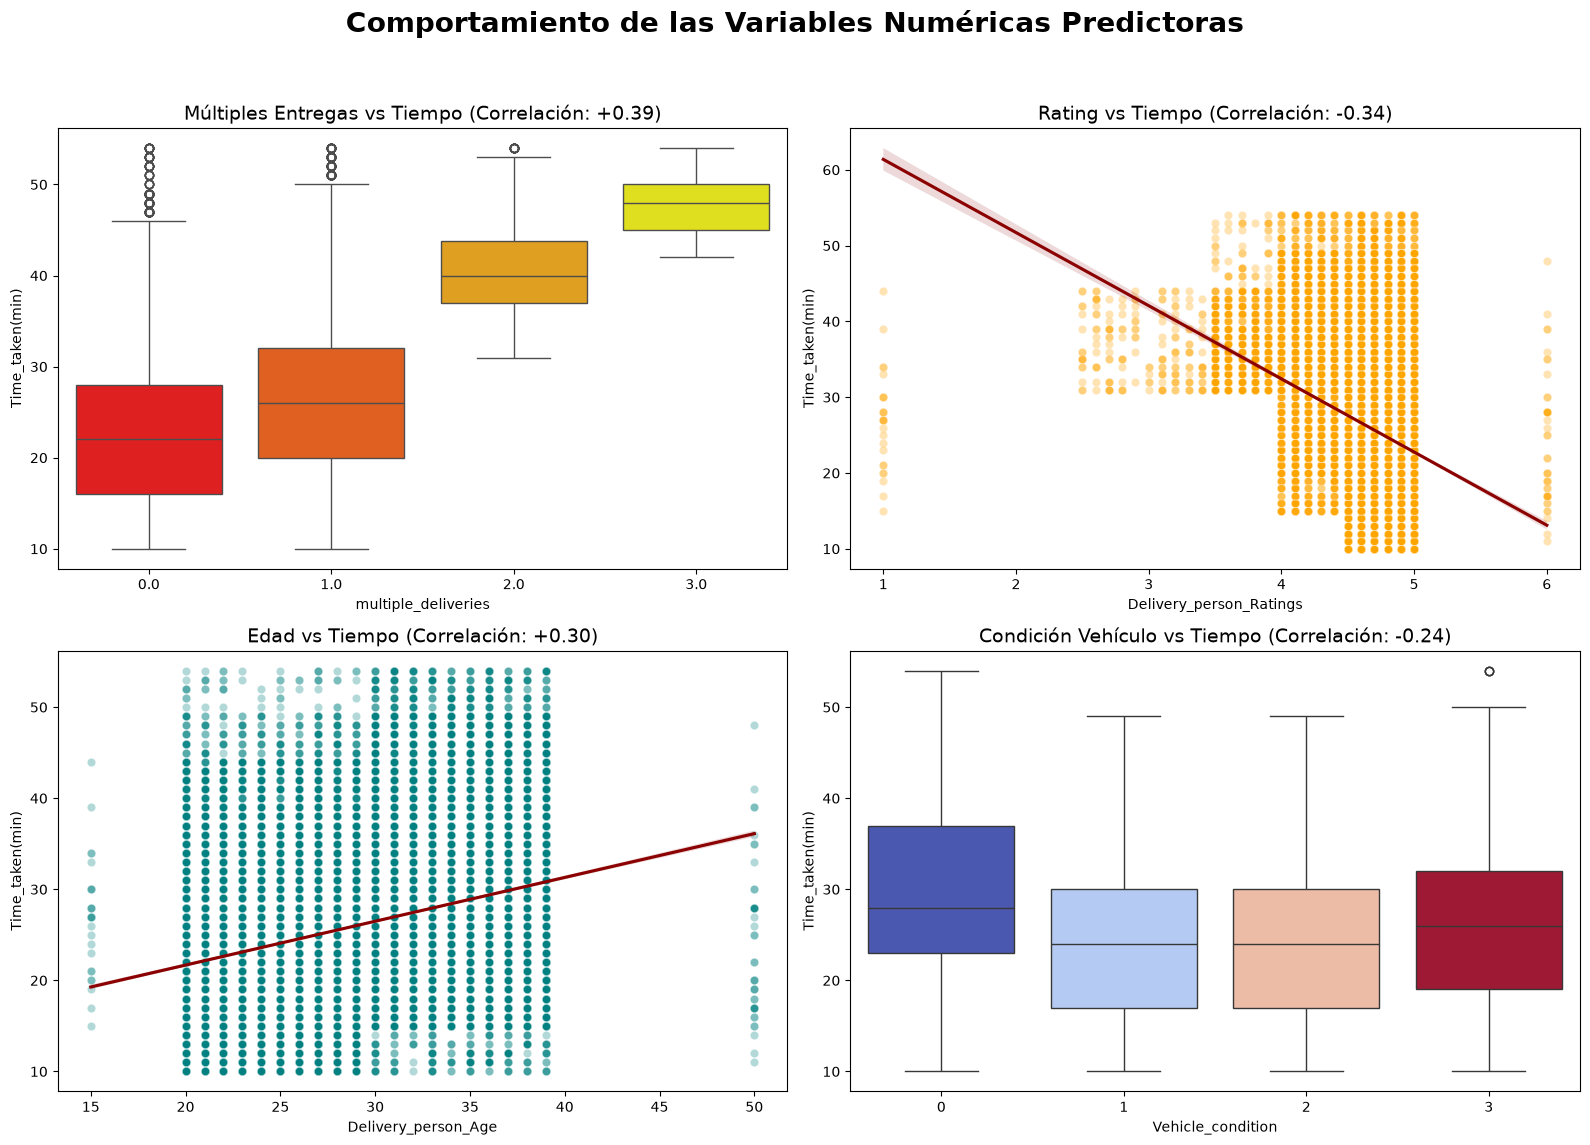

In [6]:
print("=====================================================================")
print(" FASE: ANÁLISIS VISUAL NUMÉRICO (PEARSON)")
print("=====================================================================\n")

fig_num, axes_num = plt.subplots(2, 2, figsize=(16, 12))
fig_num.suptitle('Comportamiento de las Variables Numéricas Predictoras', fontsize=20, fontweight='bold', y=0.98)

# 1. Múltiples Entregas (Discreto)
sns.boxplot(x='multiple_deliveries', y='Time_taken(min)', data=df_limpio, palette='autumn', ax=axes_num[0, 0], hue='multiple_deliveries', legend=False)
axes_num[0, 0].set_title('Múltiples Entregas vs Tiempo (Correlación: +0.39)', fontsize=14)

# 2. Calificación (Continuo)
sns.scatterplot(x='Delivery_person_Ratings', y='Time_taken(min)', alpha=0.3, color='orange', data=df_limpio, ax=axes_num[0, 1])
sns.regplot(x='Delivery_person_Ratings', y='Time_taken(min)', data=df_limpio, scatter=False, color='darkred', ax=axes_num[0, 1])
axes_num[0, 1].set_title('Rating vs Tiempo (Correlación: -0.34)', fontsize=14)

# 3. Edad (Continuo)
sns.scatterplot(x='Delivery_person_Age', y='Time_taken(min)', alpha=0.3, color='teal', data=df_limpio, ax=axes_num[1, 0])
sns.regplot(x='Delivery_person_Age', y='Time_taken(min)', data=df_limpio, scatter=False, color='darkred', ax=axes_num[1, 0])
axes_num[1, 0].set_title('Edad vs Tiempo (Correlación: +0.30)', fontsize=14)

# 4. Condición del Vehículo (Discreto)
sns.boxplot(x='Vehicle_condition', y='Time_taken(min)', data=df_limpio, palette='coolwarm', ax=axes_num[1, 1], hue='Vehicle_condition', legend=False)
axes_num[1, 1].set_title('Condición Vehículo vs Tiempo (Correlación: -0.24)', fontsize=14)

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()